In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from fun_track_fast import count_raw_topological_events,plot_diameter_tree_v1, \
                           clean_genealogy_from_raw_history,print_cleaning_summary
import numpy as np

In [2]:
from def_cases import Case_mp  # Import case class from def_case.py
import read_case  # Import read_case.py to apply updates
from param_fig import set_fig_params
from read_case import (
    cases_ReL_038_We06p0_dL1p49,
    cases_ReL_038_We15p0_dL1p49
)

PATH = /usr/licensed/anaconda3/2021.11/bin:/usr/share/Modules/bin:/usr/local/bin:/usr/local/sbin:/usr/bin:/usr/sbin:/opt/puppetlabs/bin:/opt/dell/srvadmin/sbin
latex   = /usr/bin/latex
pdflatex= /usr/bin/pdflatex
dvipng  = /usr/bin/dvipng


In [3]:
ens = 19
print(cases_ReL_038_We15p0_dL1p49[ens])
cases = cases_ReL_038_We15p0_dL1p49

Case_mp(ReL=38, WeD=15, d0l=1.49, R0=8.318876, sigma=62.19818, amp=0.1, mu1_in=1.84, rho_r=1.0, res=10, nens=19, work_dir='/scratch/gpfs/DEIKE/ns8802/bubbles/multiphase/ReL_038_WeD15_d0l1p49_Leq10/s19/', mean_eps=8.9232, rho1=1.0, mu1=1.84, rho2=0.001176470588235294, mu2=0.0736, ted=3.1421208793303177, d_h=6.334511234016359, Oh_l=0.057198107725307014)


In [4]:
#
# ============================================================
# PARAMETERS
# ============================================================
#
#
general_path = Path("/scratch/gpfs/DEIKE/ns8802/bubbles/multiphase/ReL_038_WeD15_d0l1p49_Leq10/statistics_tracking/statistics_output/");
res = cases[ens].res
is_2d = 0
lbox_v = [120,120,120]
periodic_bc = [1,1,1]
separation_veto = True
#
rho_liq = cases[ens].rho_r
mu_liq = cases[ens].mu1_in
sigma = cases[ens].sigma
d_h = cases[ens].d_h
t_h = 1/np.sqrt(12)*np.sqrt(rho_liq/sigma)*d_h**1.5
do_debug = False
#

In [5]:
#
# ============================================================
# WORKING DIRS
# ============================================================
#
case = f"{ens:02d}"
work_dir = general_path / f"s{case}"
raw_history_file       = work_dir / "event_history_raw.out"
initial_genealogy_file = work_dir / "initial_genealogy.json"
#

In [6]:
print(raw_history_file)

/scratch/gpfs/DEIKE/ns8802/bubbles/multiphase/ReL_038_WeD15_d0l1p49_Leq10/statistics_tracking/statistics_output/s19/event_history_raw.out


In [7]:
#
# ============================================================
# LOAD INITIAL GENEALOGY
# ============================================================
#
with open(initial_genealogy_file,"r") as f:
    initial_data = json.load(f)
#
idx_to_id_initial = {
    int(k):v
    for k,v in initial_data["idx_to_id_initial"].items()
}
#
id_to_birth_time_initial = {
    k:float(v)
    for k,v in initial_data["id_to_birth_time_initial"].items()
}
#
Nb_initial = int(initial_data["Nb_initial"])
istep_initial = int(initial_data["istep_initial"])
time_initial = float(initial_data["time_initial"])
is_2d = int(initial_data["is_2d"])
#
print("Initial genealogy loaded")
print("Nb_initial =",Nb_initial)
print("istep_initial =",istep_initial)
print("time_initial =",time_initial)
#

Initial genealogy loaded
Nb_initial = 1
istep_initial = 675521
time_initial = 7603.2001845


In [8]:
#
# ============================================================
# LOAD RAW EVENT HISTORY
# ============================================================
#
event_history_raw = []
#
with open(raw_history_file,"r") as f:
    for line in f:
        if line.strip():
            event_history_raw.append(json.loads(line))
#
if len(event_history_raw) == 0:
    raise RuntimeError(
        f"No records found in {raw_history_file}"
    )
#
print("event_history_raw loaded:",len(event_history_raw),"records")
tend = event_history_raw[-1]["time_p1"]
print("end time =", tend)
#
# ============================================================
# SAFETY CHECK INITIAL STATE
# ============================================================
#
n0_raw = len(event_history_raw[0]["voll0"])
#
if len(idx_to_id_initial) != n0_raw:
    raise RuntimeError(
        "Initial genealogy does not match first raw-history frame.\n"
        f"Initial IDs = {len(idx_to_id_initial)}\n"
        f"First raw frame bubbles = {n0_raw}"
    )
#
if set(idx_to_id_initial.values()) != set(id_to_birth_time_initial.keys()):
    raise RuntimeError(
        "Mismatch between initial physical IDs and birth-time IDs."
    )
#
# ============================================================
# RAW TOPOLOGICAL EVENT COUNTS
# ============================================================
#
(
    total_breakups_raw,
    total_coalescences_raw,
    raw_event_series,
) = count_raw_topological_events(event_history_raw)
#
print("")
print("==============================================")
print("RAW TOPOLOGICAL EVENTS")
print("==============================================")
print("Total raw breakups     =", total_breakups_raw)
print("Total raw coalescences =", total_coalescences_raw)
print("==============================================")
#
# ============================================================
# CLEAN PHYSICAL GENEALOGY
# ============================================================
#
cleaned = clean_genealogy_from_raw_history(
        event_history_raw,
        idx_to_id_initial,
        id_to_birth_time_initial,
        rho_liq,
        mu_liq,
        sigma,
        is_2d,
        debug=do_debug,
        lbox_v=lbox_v,
        periodic_bc=periodic_bc,
        separation_veto=separation_veto)
#
print_cleaning_summary(cleaned,total_breakups_raw,total_coalescences_raw)
total_breakups = cleaned["total_breakups"]
total_coalescences = cleaned["total_coalescences"]
breakup_event = cleaned["breakup_event"]
diameter_tree = cleaned["diameter_tree"]
diameter_history = cleaned["diameter_history"]
physical_event_history = cleaned["physical_event_history"]
bubble_lifetime = cleaned["bubble_lifetime"]
idx_to_id_final = cleaned["idx_to_id_final"]
id_to_birth_time = cleaned["id_to_birth_time"]
genealogy = cleaned["genealogy"]
#
# ============================================================
# CLEAN TOPOLOGICAL EVENT COUNTS
# ============================================================
#
print("")
print("==============================================")
print("CLEAN TOPOLOGICAL EVENTS")
print("==============================================")
print("Total clean breakups     =", total_breakups)
print("Total clean coalescences =", total_coalescences)
print("Removed breakups         =", total_breakups_raw-total_breakups)
print("Removed coalescences     =", total_coalescences_raw-total_coalescences)
print("==============================================")
#

event_history_raw loaded: 74671 records
end time = 7710.875

RAW TOPOLOGICAL EVENTS
Total raw breakups     = 83864
Total raw coalescences = 83819

RESOLUTION-BASED CLEANING
Raw breakups / coalescences      = 83864 / 83819
Physical breakups / coalescences = 8215 / 8174
Transient breakups (A->B+C->A)   = 2827
Transient coalescences           = 10508
Sheddings of unresolved debris   = 62314
Absorptions of unresolved debris = 62310
Emergences (debris -> resolved)  = 0
Candidate reversals kept as real = 544
   coalesc. t=7607->7607  vol=5.72  dt_min/t_window=0.00
   coalesc. t=7610->7612  vol=7.08  dt_min/t_window=0.26
   breakup  t=7612->7612  vol=0.00  dt_min/t_window=0.00  sep=1.24
   coalesc. t=7613->7618  vol=0.02  dt_min/t_window=1.95
   coalesc. t=7615->7615  vol=5.16  dt_min/t_window=0.02
   coalesc. t=7615->7618  vol=5.20  dt_min/t_window=0.78
   breakup  t=7616->7618  vol=0.00  dt_min/t_window=1.18  sep=22.30
   breakup  t=7616->7617  vol=0.02  dt_min/t_window=0.20  sep=10.80
   c

In [9]:
#stop

In [10]:
BREAKUP_TYPES = {"breakup"}   # add "transient_breakup" if you want those too
#
breakup_children = {}   # child_id  -> time it was born by breakup
breakup_parents  = {}   # parent_id -> time it died by breakup
#
for record in physical_event_history:
    for event in record["events"]:
        if event.get("type") not in BREAKUP_TYPES:
            continue
        t_event = event["time"]
        breakup_parents[event["parent"]] = t_event
        for cid in event["children"]:
            breakup_children[cid] = t_event
#
print("breakup births :", len(breakup_children))
print("breakup deaths :", len(breakup_parents))

breakup births : 16430
breakup deaths : 8215


In [11]:
#
# ============================================================
# BUBBLE LIFETIME VS DIAMETER
# ============================================================
T_eddy = cases[ens].ted
n_eddy = 4.0
t_window_start = time_initial
t_window_end   = time_initial + n_eddy * T_eddy
tol = 1e-12 * max(1.0, abs(t_window_end))   # float-comparison safety

D_life, t_life = [], []
n_rejected = {"window": 0, "incomplete": 0, "not_born_breakup": 0,
              "not_died_breakup": 0, "no_diameter": 0}

for physical_id, life_data in bubble_lifetime.items():
    t_birth  = life_data["t_birth"]
    t_death  = life_data["t_death"]
    lifetime = life_data["t_life"]

    # born within the first 4 eddy turnovers
    if t_birth is None or not (t_window_start - tol <= t_birth <= t_window_end + tol):
        n_rejected["window"] += 1
        continue

    # complete lifetime
    #if t_death is None or lifetime is None:
    #    n_rejected["incomplete"] += 1
    #    continue

    # born by breakup
    #if physical_id not in breakup_children:
    #    n_rejected["not_born_breakup"] += 1
    #    continue

    # died by breakup
    #if physical_id not in breakup_parents:
    #    n_rejected["not_died_breakup"] += 1
    #    continue

    # diameter history
    #if physical_id not in diameter_history:
    #    n_rejected["no_diameter"] += 1
    #    continue
    diameters = np.asarray(diameter_history[physical_id]["diameter"], dtype=float)
    #if diameters.size == 0:
    #    n_rejected["no_diameter"] += 1
    #    continue

    D_life.append(diameters[0])   # diameter right after birth
    t_life.append(lifetime)

D_life = np.asarray(D_life)
t_life = np.asarray(t_life)

print("kept:", len(D_life))
print("rejected:", n_rejected)
#

kept: 2116
rejected: {'window': 22489, 'incomplete': 0, 'not_born_breakup': 0, 'not_died_breakup': 0, 'no_diameter': 0}


In [12]:
def D_at(pid, t, side="after"):
    h = diameter_history.get(pid)
    if h is None: return None
    tt = np.asarray(h["time"]); dd = np.asarray(h["diameter"])
    order = np.argsort(tt); tt, dd = tt[order], dd[order]
    m = tt >= t if side == "after" else tt <= t
    if not m.any(): return None
    return dd[m][0] if side == "after" else dd[m][-1]

rows = []
for record in physical_event_history:
    for ev in record["events"]:
        if ev.get("type") not in BREAKUP_TYPES: continue
        t, p, ch = ev["time"], ev["parent"], ev["children"]
        Dp = D_at(p, t, "before")
        Dc = [D_at(c, t, "after") for c in ch]
        if Dp is None or any(d is None for d in Dc): continue
        Dc = np.asarray(Dc)
        rows.append(dict(
            t=t, parent=p, n_child=len(ch),
            parent_in_children=p in ch,
            vol_ratio=(Dc**3).sum() / Dp**3,       # expect ~1
            max_ratio=Dc.max() / Dp,               # expect <= 1
            min_ratio=Dc.min() / Dp,               # expect < 0.8 for binary
            first_is_birth=[np.min(diameter_history[c]["time"]) >= t - 1e-12 for c in ch],
        ))

import pandas as pd
df = pd.DataFrame(rows)
print(df.describe())
print("children count distribution:\n", df.n_child.value_counts())
print("parent ID reused as child:", df.parent_in_children.mean())
print("events with a child history starting BEFORE the event:",
      (~df.first_is_birth.apply(all)).mean())
print(df.sort_values("vol_ratio").head(10))

                 t  n_child    vol_ratio    max_ratio    min_ratio
count  8215.000000   8215.0  8215.000000  8215.000000  8215.000000
mean   7670.665782      2.0     1.005497     0.999551     0.160619
std      30.166100      0.0     0.013038     0.006710     0.062835
min    7606.611564      2.0     0.997126     0.808191     0.060566
25%    7648.061777      2.0     1.001394     0.999903     0.118627
50%    7674.206509      2.0     1.002997     0.999972     0.147284
75%    7695.814710      2.0     1.007671     1.000026     0.200204
max    7710.704381      2.0     1.829515     1.001377     0.939681
children count distribution:
 2    8215
Name: n_child, dtype: int64
parent ID reused as child: 0.0
events with a child history starting BEFORE the event: 0.0
                t                                             parent  n_child  \
3337  7669.560178  b0_B1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C...        2   
3352  7669.605233  b0_B1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C1_C...        2

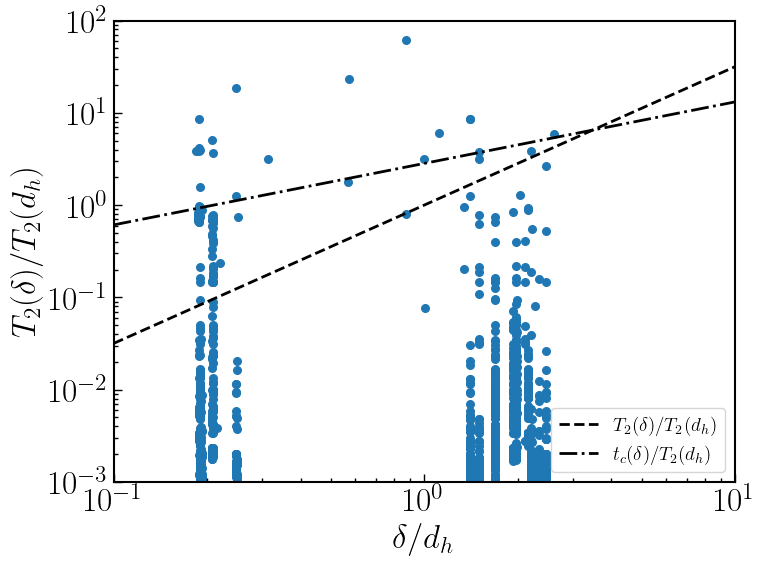

In [13]:
#
# ============================================================
# PLOT
# ============================================================
#
set_fig_params()
fig,ax = plt.subplots(figsize=(8,6))
#
d_v = np.linspace(0.1,10,512)
thd = d_v**(3/2)
pre = np.sqrt(12)*cases[ens].mean_eps**(-1/3)*cases[ens].d_h**(-5/6)/(np.sqrt(cases[ens].rho1/cases[ens].sigma))
tch = pre*d_v**(2./3)
#
ax.scatter(D_life/d_h,t_life/t_h,s=30)
ax.plot(d_v,thd,"k--",linewidth=2.0,label=r"$T_2(\delta)/T_2(d_h)$")
ax.plot(d_v,tch,"k-.",linewidth=2.0,label=r"$t_c(\delta)/T_2(d_h)$")
#
ax.set_xlim([0.1,10])
ax.set_ylim([10**(-3),10**2])
ax.set_xlabel(r"$\delta/d_h$")
ax.set_ylabel(r"$T_2(\delta)/T_2(d_h)$")
ax.legend(loc="lower right",fontsize=14)
#
ax.set_xscale("log")
ax.set_yscale("log")
#
plt.tight_layout()
plt.show()
#

In [14]:
print(diameters)

[1.9883809  1.98944957 1.98694838 ... 1.98731203 1.98745032 1.98862382]
